In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

In [8]:
df = pd.read_csv("mobiles.csv")
df.head(5)

,Company Name,Model Name,Mobile Weight,RAM,Front Camera,Back Camera,Processor,Battery Capacity,Screen Size,Launched Price (China),Launched Price (USA),Launched Price (Dubai),Launched Year
0,Apple,iPhone 16 128GB,174,6,12,48,A17 Bionic,3600,6,5799,799,2799,2024
1,Apple,iPhone 16 256GB,174,6,12,48,A17 Bionic,3600,6,6099,849,2999,2024
2,Apple,iPhone 16 512GB,174,6,12,48,A17 Bionic,3600,6,6499,899,3199,2024
3,Apple,iPhone 16 Plus 128GB,203,6,12,48,A17 Bionic,4200,6,6199,899,3199,2024
4,Apple,iPhone 16 Plus 256GB,203,6,12,48,A17 Bionic,4200,6,6499,949,3399,2024


Внутри датасета содержатся следующие характеристики:

1. `Company Name` – бренд или производитель мобильного устройства

2. `Model Name` – модель мобильного устройства

3. `Mobile Weight` – масса мобильного устройства (в граммах)

4. RAM – размер оперативной памяти устройства (в Гб)

5. `Front Camera` – разрешение фронтальной камеры (в Мп)

6. `Back Camera` – разрешение основной камеры заднего вида (в Мп)

7. Processor – процессор, используемый в устройстве

8. `Battery Capacity` – емкость аккумулятора устройства (в мА⋅ч)

9. `Screen Size` – размер дисплея устройства (в дюймах)

10. `Launched Price` (China - китайские юани, USA - доллары США, Dubai - дирхамы ОАЭ) – официальная
цена при запуске продаж мобильного устройства в соответствующей стране на момент выпуска. Цена
варьируется в зависимости от года выпуска мобильного устройства.

11. `Launched Year` – год официального выпуска мобильного устройства

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 930 entries, 0 to 929
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Company Name            930 non-null    str  
 1   Model Name              930 non-null    str  
 2   Mobile Weight           930 non-null    int64
 3   RAM                     930 non-null    int64
 4   Front Camera            930 non-null    int64
 5   Back Camera             930 non-null    int64
 6   Processor               930 non-null    str  
 7   Battery Capacity        930 non-null    int64
 8   Screen Size             930 non-null    int64
 9   Launched Price (China)  930 non-null    int64
 10  Launched Price (USA)    930 non-null    int64
 11  Launched Price (Dubai)  930 non-null    int64
 12  Launched Year           930 non-null    int64
dtypes: int64(10), str(3)
memory usage: 94.6 KB


In [16]:
df[df.duplicated(keep=False)]
# len(df[df.duplicated(keep=False)])

df = df.drop_duplicates()
df.shape

(915, 13)

In [ ]:
# 1. Постройте столбчатую диаграмму, показывающую распределение общего объема моделей устройств 
# среди всех производителей. Над каждым столбцом диаграммы укажите соответствующее количество 
# моделей для данного бренда. Определите Топ-5 брендов по количеству произведенных моделей.

In [20]:
comapanies = df["Company Name"].value_counts()
comapanies

Company Name
Oppo        115
Apple        97
Honor        91
Samsung      88
Vivo         86
Realme       69
Motorola     62
Infinix      55
OnePlus      53
Huawei       42
Tecno        39
POCO         30
Xiaomi       27
Google       21
Lenovo       15
Nokia        11
Sony          9
iQOO          3
Poco          2
Name: count, dtype: int64

In [24]:
comapanies.index

Index(['Oppo', 'Apple', 'Honor', 'Samsung', 'Vivo', 'Realme', 'Motorola',
       'Infinix', 'OnePlus', 'Huawei', 'Tecno', 'POCO', 'Xiaomi', 'Google',
       'Lenovo', 'Nokia', 'Sony', 'iQOO', 'Poco'],
      dtype='str', name='Company Name')

In [25]:
comapanies.values

array([115,  97,  91,  88,  86,  69,  62,  55,  53,  42,  39,  30,  27,
        21,  15,  11,   9,   3,   2])

In [31]:
for i, value in enumerate(comapanies):
    print(i, value)

0 115
1 97
2 91
3 88
4 86
5 69
6 62
7 55
8 53
9 42
10 39
11 30
12 27
13 21
14 15
15 11
16 9
17 3
18 2


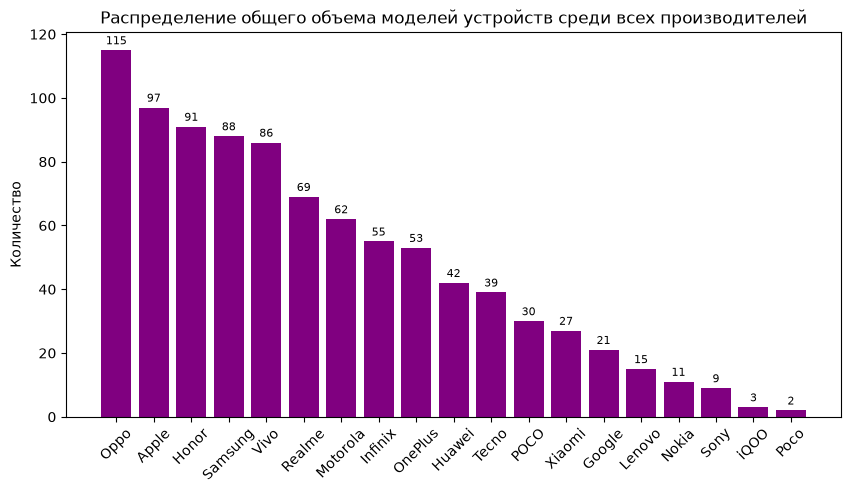

In [45]:
plt.figure(figsize=(10, 5))

plt.bar(
    x=comapanies.index,
    height=comapanies.values,
    color="purple"
)

for i, value in enumerate(comapanies):
    plt.text(
        x=i,
        y=value+1,
        s=str(value),
        ha="center",
        va="bottom",
        fontsize=8,
    )

plt.title("Pаспределение общего объема моделей устройств среди всех производителей")
plt.ylabel("Количество")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# 2. Проверьте гипотезу: «С годами средняя емкость аккумуляторов мобильных устройств увеличивается». 
# Для проверки гипотезы постройте линейный график, показывающий изменение средней емкости аккумулятора устройств по годам. 
# На оси X расположите год выпуска, на оси Y — среднюю емкость аккумулятора.
# Верна ли гипотеза? В ответе напишите “верно” или “ложь”.

In [53]:
df.head(1)
df_3 = df.groupby("Launched Year")["Battery Capacity"].mean().reset_index().sort_values(by="Launched Year", ascending=True)
df_3

,Launched Year,Battery Capacity
0,2014,2150.000000
1,2016,3920.000000
2,2017,3220.777778
3,2018,3177.952381
4,2019,3950.717391
5,2020,4967.275510
6,2021,4617.252427
7,2022,4992.465753
8,2023,5301.126374
9,2024,5418.127148


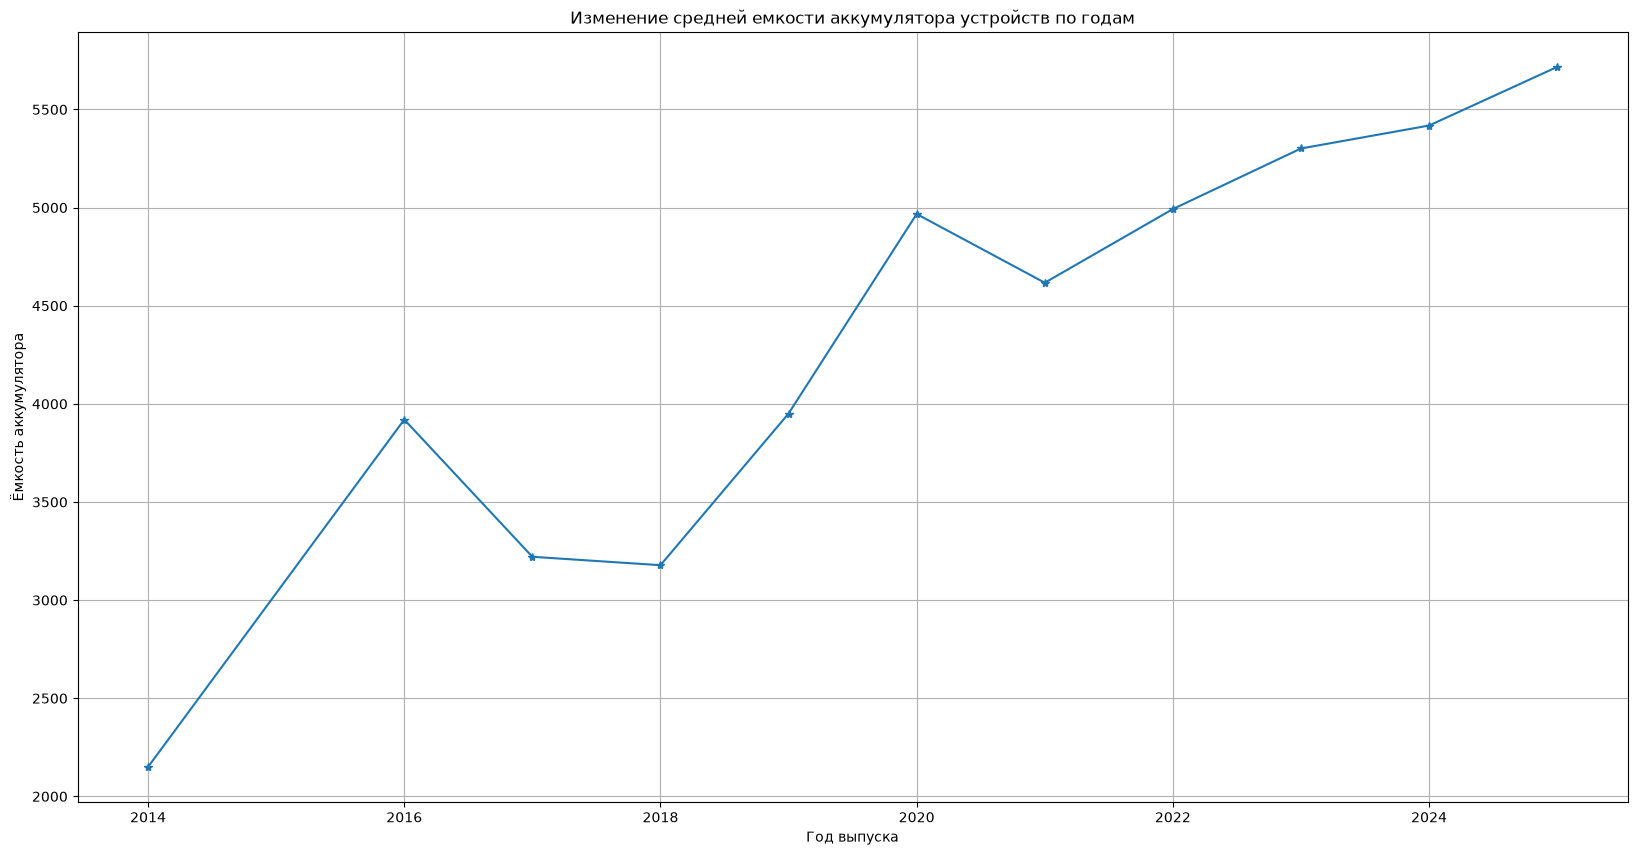

In [65]:
plt.figure(figsize=(20, 10))

plt.plot(
    df_3["Launched Year"],
    df_3["Battery Capacity"],
    marker="*"
)

plt.xlabel("Год выпуска")
plt.ylabel("Ёмкость аккумулятора")
plt.title("Изменение средней емкости аккумулятора устройств по годам")
plt.grid()
plt.show()